# Step 7a: Candidate 2 of 4, Ridge on log1p(target)

**Decisions for step 7:** the winner is chosen by **R² in £** (MAE breaks ties), from **5-fold CV on the train snapshot only**; hyperparameters are tuned with **Optuna**; features are **R, F, M only** for now. Test is **not touched** in this notebook.

## The model
`log1p(R, F, M)` &rarr; `StandardScaler` &rarr; `Ridge` &rarr; predicts `log1p(future spend)` &rarr; convert back to £ &rarr; score in £.

- Why log: spend is heavily skewed (step 5); after `log1p` it is roughly symmetric, which a linear model likes.
- Ridge has one knob, **alpha** (how hard the coefficients are shrunk). Optuna searches it (250 trials, log scale, 0.001 to 1,000,000).
- **The catch is converting back.** `expm1` of the average log is a *typical* value, not the *average* (Jensen's inequality), so totals come out too low. **Duan smearing** multiplies by the mean of `exp(training residuals)` to correct that. We tune and report both variants.

Code: `src/step7a_ridge_log.py`, `src/tuning.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from metrics import r2
from step3_split import load_ledger, make_snapshot, TRAIN_CUTOFF
from step4_rfm import build_rfm
from step6_baselines import BASELINES, cv_predictions, score_table
from step7a_ridge_log import LogRidge, suggest_alpha, N_TRIALS
from tuning import tune

pd.set_option("display.width", 200)
train = make_snapshot(load_ledger(), TRAIN_CUTOFF)
X, y = build_rfm(train), train.target
y_arr = y.to_numpy()
len(X)

/data/home/mitanshub/miniconda3/envs/ml_clv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


4242

## 1. Tune alpha with Optuna (R² in £ from 5-fold CV)

Each trial picks an alpha, runs the 5-fold CV, pools the out-of-fold predictions, and returns R² in £. The same folds are used for every trial and every model.

LogRidge (plain expm1)     best alpha    1,050.1 | best CV R2 0.398


LogRidge + smearing        best alpha    4,829.2 | best CV R2 0.549


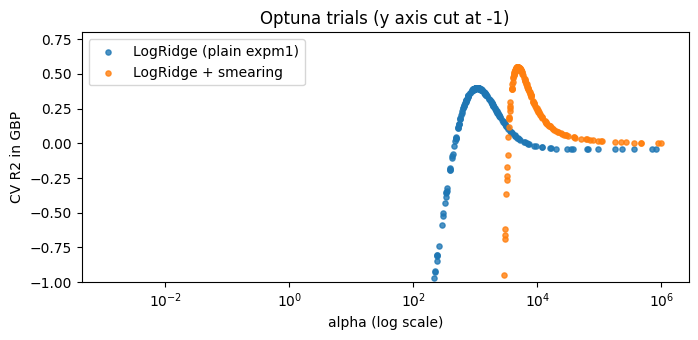

In [2]:
studies = {}
for smear in (False, True):
    label = "LogRidge + smearing" if smear else "LogRidge (plain expm1)"
    studies[label] = tune(lambda alpha, s=smear: LogRidge(alpha=alpha, smear=s), suggest_alpha, X, y, n_trials=N_TRIALS)
    print(f"{label:26s} best alpha {studies[label].best_params['alpha']:>10,.1f} | best CV R2 {studies[label].best_value:.3f}")

fig, ax = plt.subplots(figsize=(7, 3.5))
for (label, st), c in zip(studies.items(), ["tab:blue", "tab:orange"]):
    a = [t.params["alpha"] for t in st.trials]; v = [t.value for t in st.trials]
    ax.scatter(a, v, s=14, label=label, color=c, alpha=0.8)
ax.set_xscale("log"); ax.set_ylim(-1, 0.8)
ax.set_xlabel("alpha (log scale)"); ax.set_ylabel("CV R2 in GBP"); ax.set_title("Optuna trials (y axis cut at -1)"); ax.legend()
plt.tight_layout()

Small alphas are terrible (R² far below 0 on the £ scale) and the score climbs as alpha grows. The best alphas are large (about 1,050 and 4,800). Reason: `exp()` of a linear prediction explodes for the biggest customers, and in £ those few customers decide R². Heavy shrinkage keeps their predictions under control.

Two things changed along the way: the first run used a range up to only 1,000 and the best alpha hit that edge, so we widened it. Later we raised the trials from 30 to 250: the best alphas barely moved, and the smearing variant's R² rose from 0.51 to 0.55.

## 2. Compare with the baselines (train CV)

In [3]:
preds = {name: cv_predictions(cls, X, y) for name, cls in BASELINES.items()}
for label, st in studies.items():
    best, smear = st.best_params["alpha"], label.endswith("smearing")
    preds[label] = cv_predictions(lambda b=best, s=smear: LogRidge(alpha=b, smear=s), X, y)

t = score_table(y_arr, preds)
t["total pred / total actual"] = [preds[k].sum() / y_arr.sum() for k in t.index]
display(t.round(3))
print("Same, without the 10 biggest customers:")
display(score_table(y_arr, preds, without_top=10).round(3))

,R2,MAE,Capture@20%,total pred / total actual
mean,-0.000,944.129,0.170,1.000
past_spend,0.746,523.153,0.739,1.001
LogRidge (plain expm1),0.398,586.254,0.720,0.276
LogRidge + smearing,0.549,575.161,0.722,0.992


Same, without the 10 biggest customers:


,R2,MAE,Capture@20%
mean,-0.006,821.868,0.186
past_spend,0.549,471.154,0.686
LogRidge (plain expm1),0.340,495.441,0.666
LogRidge + smearing,0.500,498.504,0.666


The last column in the first table is **not** one of our three metrics. It is a diagnostic: total predicted £ divided by total actual £ (1.0 = totals match). It shows the Jensen effect directly:
- **plain expm1 predicts only about 28% of the real total.** That is the "typical value, not the average" problem.
- **smearing brings it to about 0.99**, and R² rises from about 0.40 to about 0.55.

## 3. Why is smearing fragile here?

Smearing multiplies every prediction by `S = mean(exp(residual))`. About half the customers have target 0 (`log1p(0) = 0`), and a few huge customers are predicted far too low, so log-scale residuals reach about +8 and `exp(8)` is about 3,000. A handful of such values dominate the mean.

In [4]:
rows = []
for alpha in (1, 100, 1000, 4829):
    m = LogRidge(alpha=alpha, smear=True).fit(X, y)
    z = np.log1p(y_arr)
    res = z - m.ridge_.predict(m.scaler_.transform(m._prep(X)))
    rows.append({"alpha": alpha, "smearing factor S": round(m.smear_, 1), "max log residual": round(res.max(), 1),
                 "in-sample R2 plain": round(r2(y_arr, LogRidge(alpha=alpha).fit(X, y).predict(X)), 2),
                 "in-sample R2 smeared": round(r2(y_arr, m.predict(X)), 1)})
pd.DataFrame(rows).set_index("alpha")

,smearing factor S,max log residual,in-sample R2 plain,in-sample R2 smeared
alpha,,,,
1,17.3,8.0,-1.88,-1284.4
100,17.1,7.9,-1.12,-951.7
1000,15.5,7.7,0.43,-110.6
4829,13.4,7.3,0.08,0.4


At small alpha the smearing factor is about 17 and the smeared in-sample R² is hugely negative. Even the plain version is negative in-sample at alpha = 1. Only strong shrinkage makes the log-linear model usable on the £ scale. This is a property of the candidate, not a bug.

## 4. Predicted vs actual (CV, log scale)

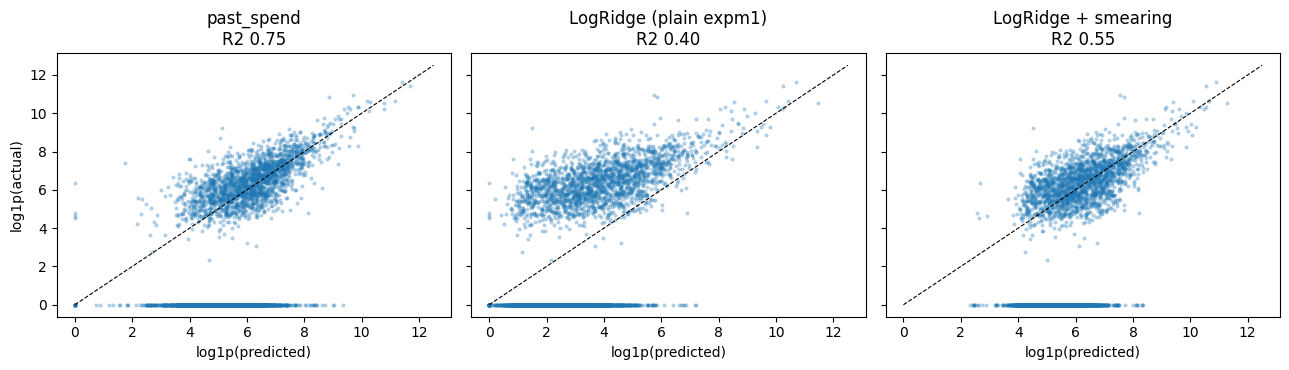

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True, sharey=True)
for ax, key in zip(axes, ["past_spend", "LogRidge (plain expm1)", "LogRidge + smearing"]):
    ax.scatter(np.log1p(preds[key]), np.log1p(y_arr), s=4, alpha=0.25)
    lim = [0, 12.5]; ax.plot(lim, lim, "k--", lw=0.8)
    ax.set_title(f"{key}\nR2 {r2(y_arr, preds[key]):.2f}"); ax.set_xlabel("log1p(predicted)")
axes[0].set_ylabel("log1p(actual)")
plt.tight_layout()

## What we learned

| Train CV | R² | MAE (£) | Capture@20% | total pred / total actual |
|---|---|---|---|---|
| mean | 0.00 | 944 | 0.17 | 1.00 |
| **past_spend** | **0.75** | **523** | **0.74** | 1.00 |
| LogRidge, plain expm1 (alpha 1,050) | 0.40 | 586 | 0.72 | 0.28 |
| LogRidge + smearing (alpha 4,829) | 0.55 | 575 | 0.72 | 0.99 |

- **Ridge on log1p does not beat past spend on our deciding metric.** R² is 0.55 at best, vs 0.75. MAE is also worse (575 vs 523).
- **Ranking is about the same.** Capture@20% is 0.72 vs 0.74. The difference is smaller than the roughly ±0.04 noise, so it is a tie, not a loss.
- **Why it loses on amounts:** it is trained to be accurate in log units, but R² in £ is decided by the biggest customers. Past spend is directly linear in £, so it gets the big customers right almost for free.
- **Smearing helps totals and R² here, but is fragile:** it needs strong shrinkage (alpha about 4,800), and it blows up at small alpha.
- Optuna picked alpha on the same CV that we report, which is slightly optimistic. With a single parameter the effect is small.
- **The CV result is stable.** Re-running the 5-fold CV with 10 different random fold assignments gave R² of 0.744 ± 0.006 (past_spend), 0.426 ± 0.014 (plain) and 0.558 ± 0.011 (smearing), and Capture@20% of 0.740, 0.720 and 0.722 with a spread of about 0.001. The gap to past spend on R² is far larger than the fold noise.
- **Open oddity (explanation not verified):** at alpha 4,829 the smeared model's *in-sample* R² (0.4, table in section 3) is lower than its CV R² (0.55). My guess is that the smearing factor S is driven by a handful of extreme residuals, so it changes a lot depending on which customers are in the fit. It is another sign that smearing is fragile here.

**Current standing by R² (train CV):** past_spend 0.75 &gt; LogRidge + smearing 0.55 &gt; XGBoost 0.50 (tuning score; honest estimate 0.48) &gt; LogRidge plain 0.40 &gt; mean 0.00.

**Next (step 7b was XGBoost on raw £; 7c is Tweedie).**